In [2]:
# Install required libraries

!pip install -q pandas numpy matplotlib seaborn scikit-learn joblib


In [3]:
from sklearn.datasets import load_breast_cancer

# Load Wisconsin Breast Cancer Dataset
data = load_breast_cancer()

print("Dataset loaded successfully!")
print("Total records:", data.data.shape[0])
print("Total features:", data.data.shape[1])
print("Feature names:", data.feature_names)
print("Target classes:", data.target_names)

Dataset loaded successfully!
Total records: 569
Total features: 30
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Target classes: ['malignant' 'benign']


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)

# Convert target into readable labels
df["diagnosis"] = pd.Series(data.target).map({
    0: "Malignant",
    1: "Benign"
})

# Display dataset
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["diagnosis"].value_counts())

Dataset shape: (569, 31)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant



Missing values: 0
Duplicate rows: 0

Class distribution:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


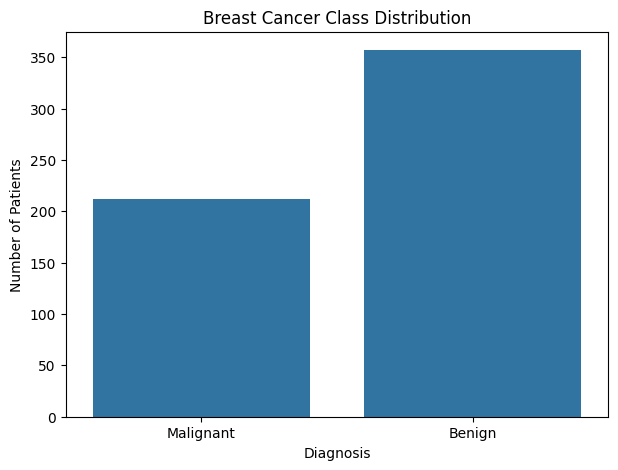

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="diagnosis"
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")
plt.show()

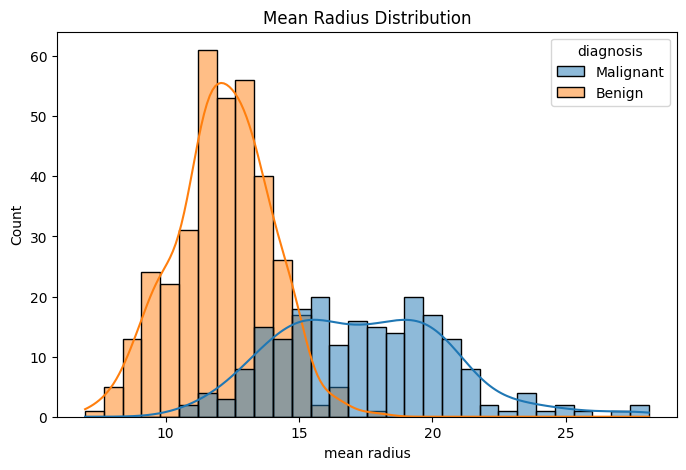

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="mean radius",
    hue="diagnosis",
    kde=True,
    bins=30
)

plt.title("Mean Radius Distribution")
plt.show()

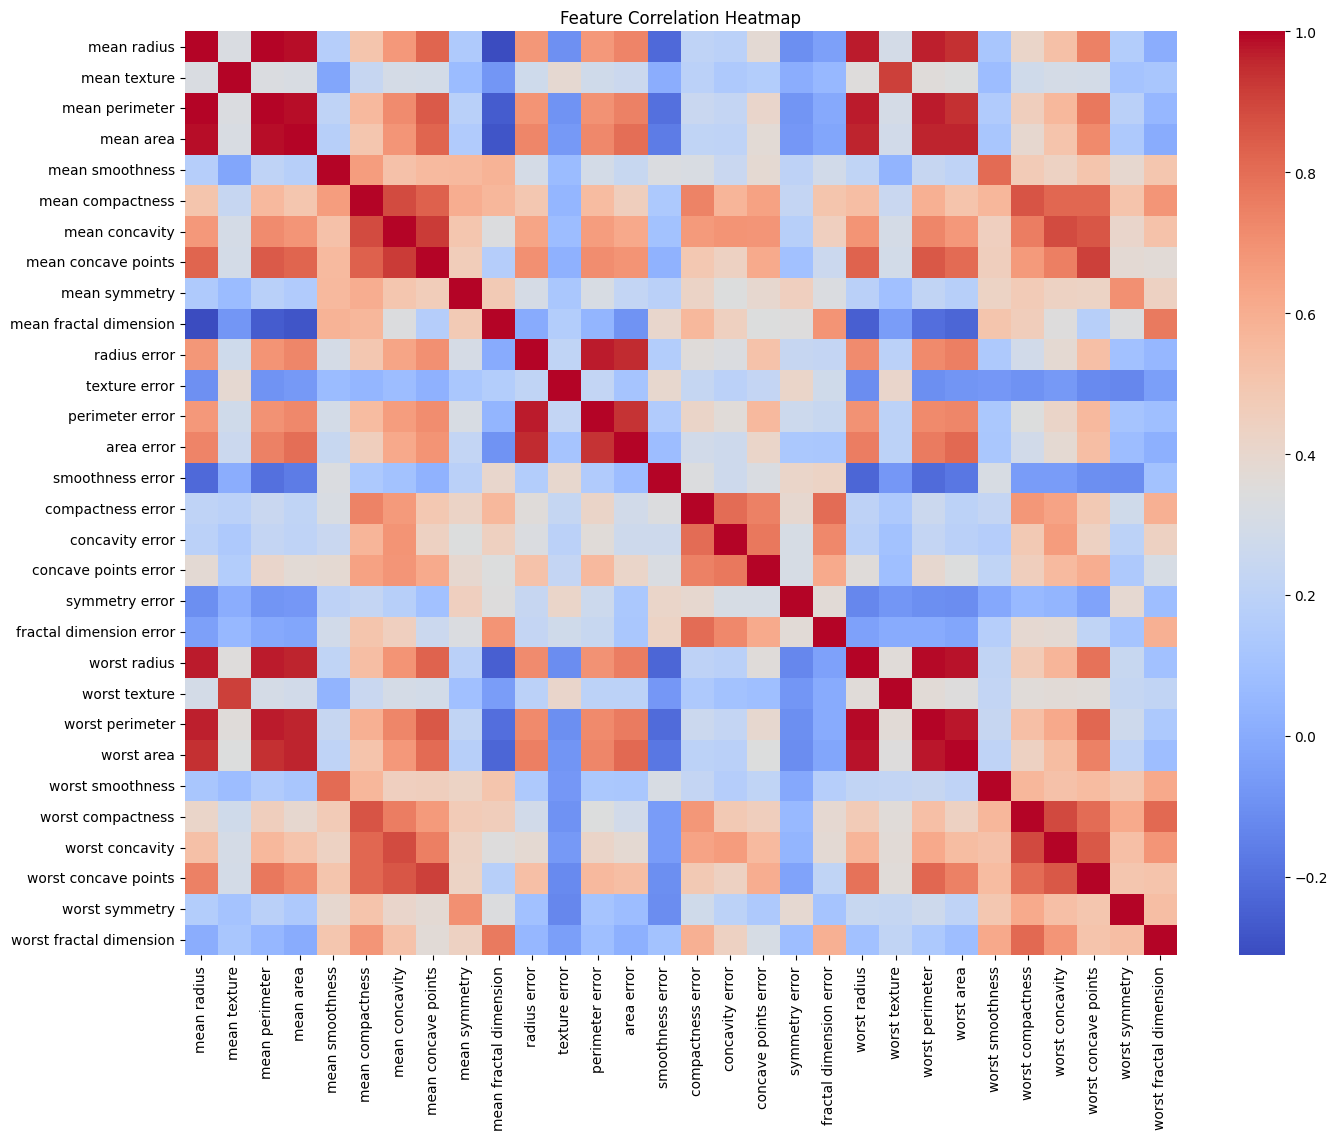

In [7]:
plt.figure(figsize=(16, 12))

correlation = df.drop(columns=["diagnosis"]).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [8]:
X = df.drop(columns=["diagnosis"])
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 455
Testing records: 114


In [9]:
import os

os.makedirs("outputs", exist_ok=True)

df.to_csv(
    "outputs/breast_cancer_processed.csv",
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [11]:
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

lr_params = {
    "model__C": [0.1, 1, 10],
    "model__solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_params,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

best_lr = lr_grid.best_estimator_

print("Logistic Regression training completed!")
print("Best Parameters:", lr_grid.best_params_)

Logistic Regression training completed!
Best Parameters: {'model__C': 0.1, 'model__solver': 'lbfgs'}


In [12]:
rf_pipeline = Pipeline([
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_

print("Random Forest training completed!")
print("Best Parameters:", rf_grid.best_params_)

Random Forest training completed!
Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [13]:
from sklearn.metrics import make_scorer, recall_score

malignant_recall = make_scorer(
    recall_score,
    pos_label=0
)

In [14]:
scoring="recall"

In [15]:
scoring=malignant_recall

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)

    # Class 0 is malignant
    malignant_probability = probabilities[:, 0]

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, pos_label=0
    )

    recall = recall_score(
        y_test, predictions, pos_label=0
    )

    f1 = f1_score(
        y_test, predictions, pos_label=0
    )

    auc = roc_auc_score(
        (y_test == 0).astype(int),
        malignant_probability
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Malignant Recall": recall,
        "F1 Score": f1,
        "AUC-ROC": auc
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Malignant Recall,F1 Score,AUC-ROC
0,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9957
1,Random Forest,0.9474,0.9286,0.9286,0.9286,0.9937


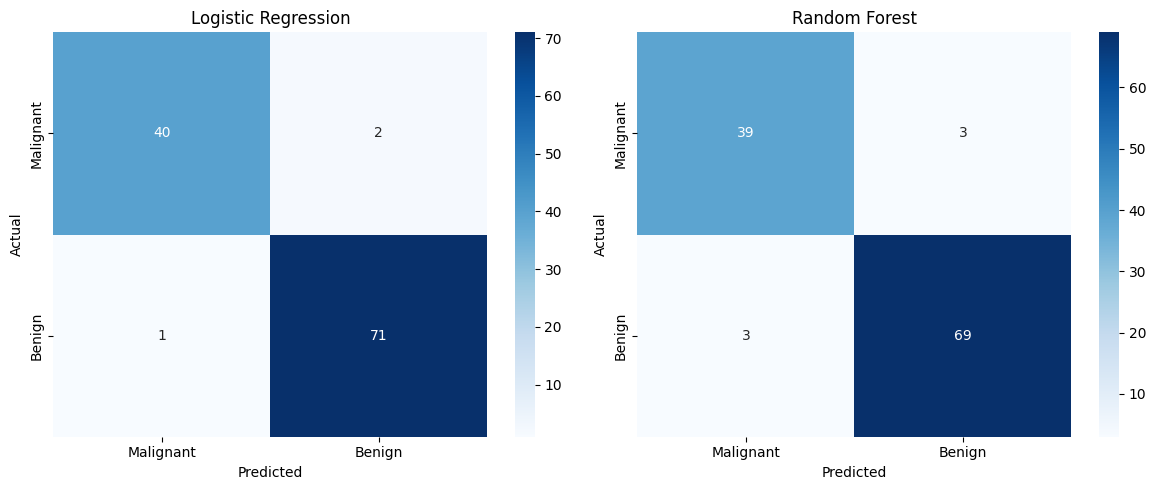

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Malignant", "Benign"],
        yticklabels=["Malignant", "Benign"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

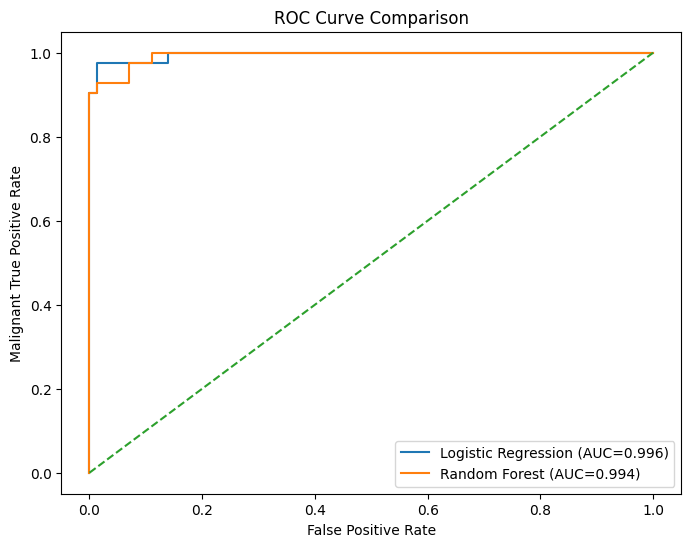

In [18]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, model in models.items():

    probabilities = model.predict_proba(X_test)[:, 0]

    fpr, tpr, thresholds = roc_curve(
        (y_test == 0).astype(int),
        probabilities
    )

    auc = roc_auc_score(
        (y_test == 0).astype(int),
        probabilities
    )

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("Malignant True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [19]:
import os
import joblib

best_result = results_df.sort_values(
    by=["Malignant Recall", "AUC-ROC"],
    ascending=False
).iloc[0]

best_model_name = best_result["Model"]
best_model = models[best_model_name]

os.makedirs("models", exist_ok=True)

joblib.dump(
    {
        "model": best_model,
        "feature_names": list(X.columns),
        "model_name": best_model_name
    },
    "models/best_model.pkl"
)

print("Best model:", best_model_name)
print("Model saved successfully!")

Best model: Logistic Regression
Model saved successfully!


In [20]:
os.makedirs("outputs", exist_ok=True)

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Evaluation results saved!")

Evaluation results saved!
